In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [2]:
path = "/kaggle/input/datasets/wisits/err123/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(path)

# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Basic data inspection
print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

display(df.head())

Shape: (7043, 21)

Data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object

Missing values:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contr

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Select numeric columns
numeric_cols = ["SeniorCitizen","tenure", "MonthlyCharges", "TotalCharges"]

# Descriptive statistics
stats = pd.DataFrame({
    "Mean": df[numeric_cols].mean(),
    "Median": df[numeric_cols].median(),
    "Mode": df[numeric_cols].mode().iloc[0],
    "Min": df[numeric_cols].min(),
    "Max": df[numeric_cols].max(),
    "Std": df[numeric_cols].std(),
    "Variance": df[numeric_cols].var(),
    "Skewness": df[numeric_cols].skew(),
    "Q1": df[numeric_cols].quantile(0.25),
    "Q3": df[numeric_cols].quantile(0.75)
})

display(stats.round(2))

# Summary of all numeric columns
display(df.describe())

# Mode of categorical columns
categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns.drop("customerID", errors="ignore")

display(df[categorical_cols].mode().iloc[0])


,Mean,Median,Mode,Min,Max,Std,Variance,Skewness,Q1,Q3
SeniorCitizen,0.16,0.00,0.00,0.00,1.00,0.37,0.14,1.83,0.00,0.00
tenure,32.37,29.00,1.00,0.00,72.00,24.56,603.17,0.24,9.00,55.00
MonthlyCharges,64.76,70.35,20.05,18.25,118.75,30.09,905.41,-0.22,35.50,89.85
TotalCharges,2283.30,1397.48,20.20,18.80,8684.80,2266.77,5138252.41,0.96,401.45,3794.74


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


gender                          Male
Partner                           No
Dependents                        No
PhoneService                     Yes
MultipleLines                     No
InternetService          Fiber optic
OnlineSecurity                    No
OnlineBackup                      No
DeviceProtection                  No
TechSupport                       No
StreamingTV                       No
StreamingMovies                   No
Contract              Month-to-month
PaperlessBilling                 Yes
PaymentMethod       Electronic check
Churn                             No
Name: 0, dtype: object

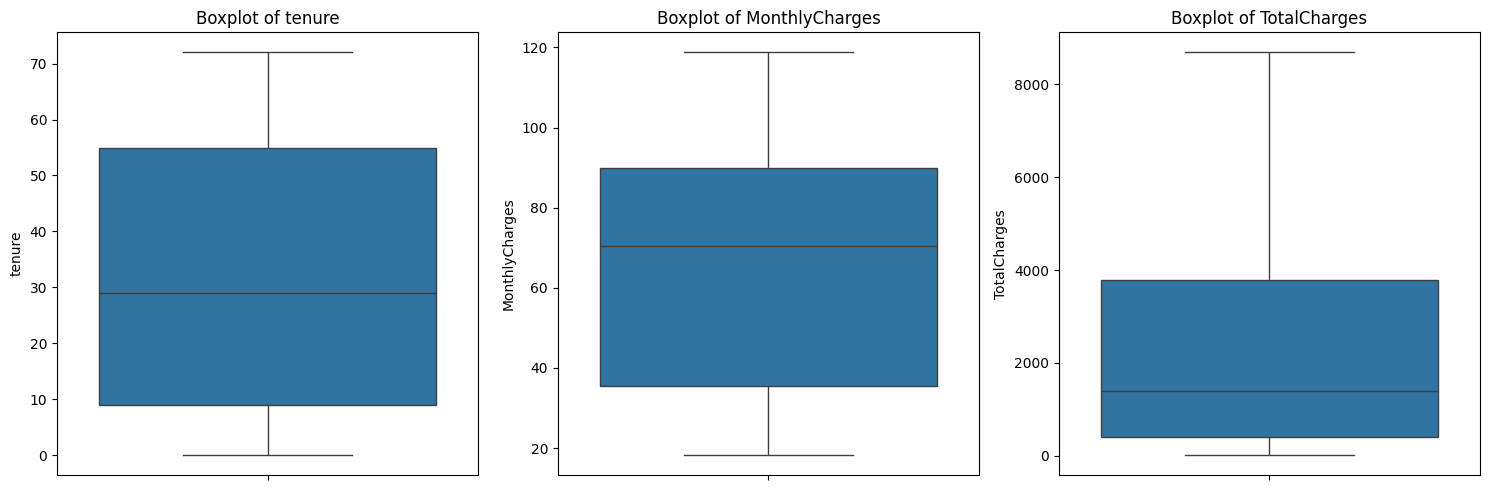

In [12]:

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(axes, numeric_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()


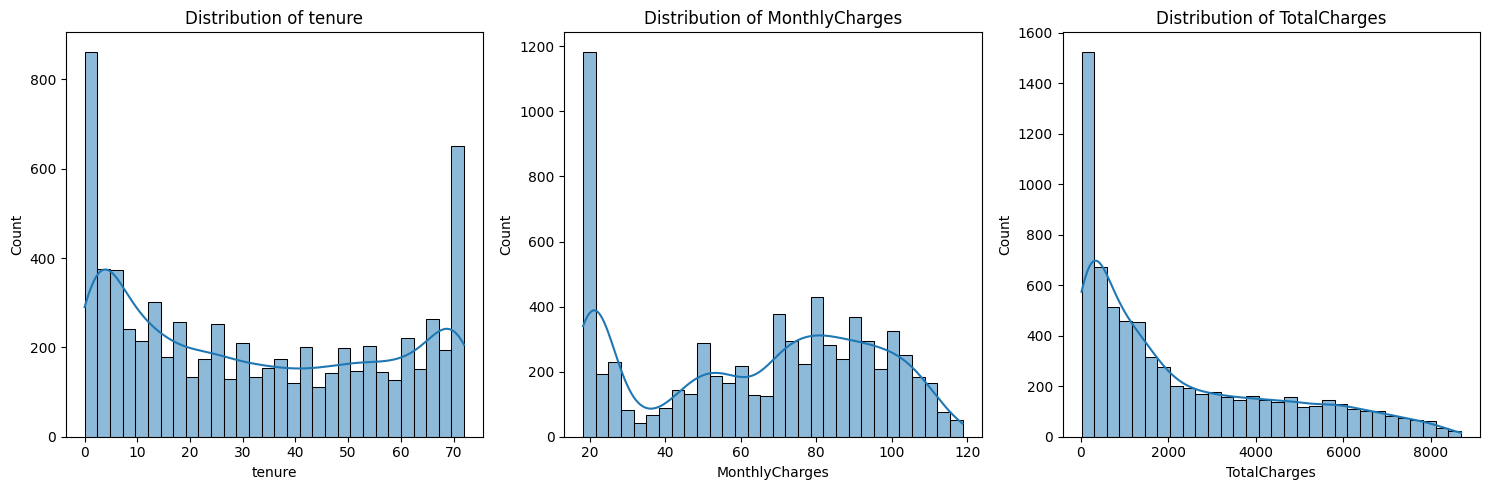

In [13]:

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(axes, numeric_cols):
    sns.histplot(
        data=df,
        x=col,
        kde=True,
        bins=30,
        ax=ax
    )
    ax.set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()


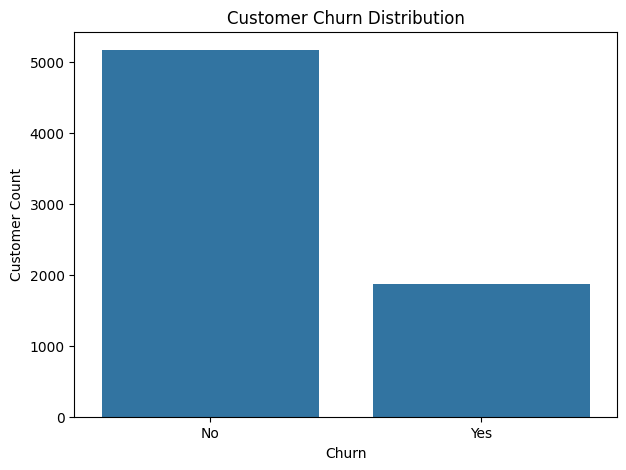

Churn percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [14]:

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Customer Count")
plt.show()

print("Churn percentage:")
print(df["Churn"].value_counts(normalize=True) * 100)


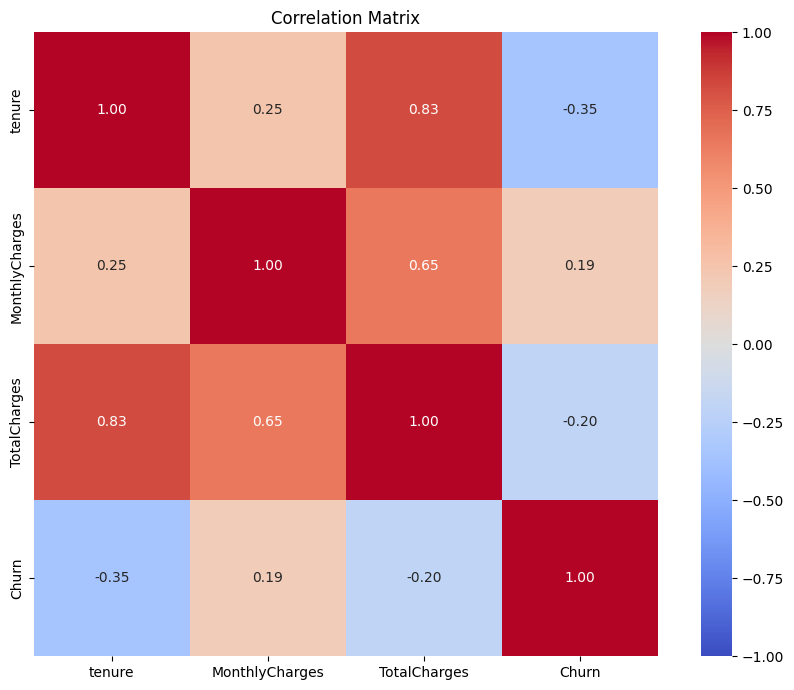

In [15]:

# Numeric features + churn target
corr_df = df[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].copy()

# Encode Churn for correlation
corr_df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Calculate correlation
corr_matrix = corr_df.corr(method="pearson")

# Plot correlation heatmap
plt.figure(figsize=(9, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()


## Scatter Plots by Churn

Each point represents one customer. Compare all three pairs of tenure, TotalCharges, and MonthlyCharges, with color indicating Churn.


In [ ]:
# Compare all pairs of numeric features, colored by churn status.
scatter_pairs = [
    ("tenure", "TotalCharges"),
    ("tenure", "MonthlyCharges"),
    ("MonthlyCharges", "TotalCharges"),
]

for x_col, y_col in scatter_pairs:
    fig, ax = plt.subplots(figsize=(12, 7))
    # Exclude missing values only for the pair being plotted.
    plot_data = df[[x_col, y_col, "Churn"]].dropna()
    sns.scatterplot(
        data=plot_data,
        x=x_col,
        y=y_col,
        hue="Churn",
        hue_order=["No", "Yes"],
        palette={"No": "#0072B2", "Yes": "#D55E00"},
        alpha=0.5,
        s=25,
        linewidth=0,
        ax=ax,
    )
    ax.set_title(f"{x_col} vs {y_col} by Churn")
    ax.set_xlabel("Tenure (months)" if x_col == "tenure" else x_col)
    ax.set_ylabel(y_col)

    plt.tight_layout()
    plt.show()


# Preprocessing
